<a href="https://colab.research.google.com/github/vishwa24816/Bell-Curve/blob/main/Bell_curve_analyser.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
# Why Stock Returns Look Like a Bell Curve

# How to run: Install the data library with `pip install yfinance` (Colab usually has it already). To analyze a different stock, change `TICKER` in Section 3 (default `SPY`). The Actual Code is run on Google Colab

## Section 1: Setup and Imports

#We import the libraries we need and fix the random seed so every simulation gives the same results on every run. We also print the library versions so you can reproduce the environment later.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import yfinance as yf

plt.style.use("seaborn-v0_8-whitegrid")
np.random.seed(42)

print("numpy      :", np.__version__)
print("pandas     :", pd.__version__)
print("matplotlib :", plt.matplotlib.__version__)
print("scipy      :", stats.__name__, "(imported)")
print("yfinance   :", yf.__version__)

numpy      : 2.1.3
pandas     : 2.2.3
matplotlib : 3.10.0
scipy      : scipy.stats (imported)
yfinance   : 0.2.66


In [13]:
## Section 2: Downloading Real Stock Data

#We download five years of daily adjusted closing prices. "Adjusted" means the prices account for dividends and stock splits, so the price changes reflect what an investor actually experienced. Change `TICKER` to study any other stock. We then print the first and last rows and count missing values.

TICKER = "SPY"   # <-- change this to any ticker, e.g. "AAPL", "MSFT", "^GSPC"
YEARS = 5

raw = yf.download(TICKER, period=f"{YEARS}y", interval="1d",
                  auto_adjust=True, progress=False)

# yfinance may return MultiIndex columns; keep just the closing prices
prices = raw["Close"].squeeze().dropna()
prices.name = TICKER

print("First rows:")
print(prices.head(), "\n")
print("Last rows:")
print(prices.tail(), "\n")
print("Trading days:", len(prices))
print("Missing values:", prices.isna().sum())

First rows:
Date
2021-10-29    429.537659
2021-11-01    430.276520
2021-11-02    432.016205
2021-11-03    434.653717
2021-11-04    436.702026
Name: SPY, dtype: float64 

Last rows:
Date
2026-10-23    759.969971
2026-10-26    765.369995
2026-10-27    769.659973
2026-10-28    772.309998
2026-10-29    769.270020
Name: SPY, dtype: float64 

Trading days: 1255
Missing values: 0


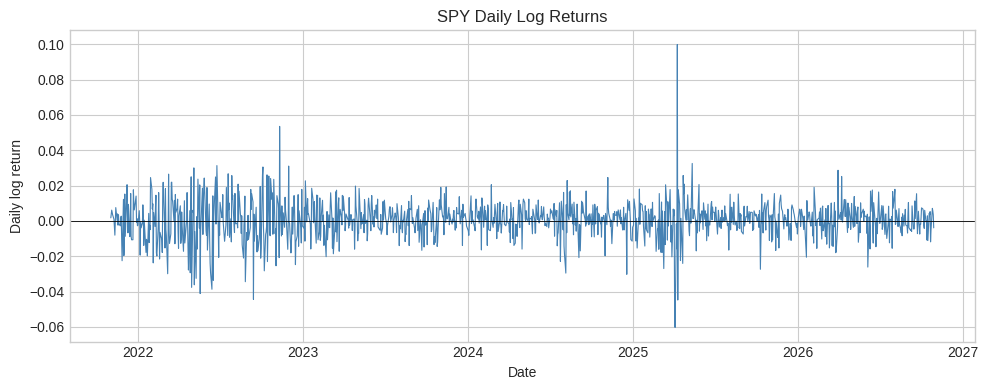

Number of daily returns: 1254


In [14]:
## Section 3: Computing Daily Log Returns

#A **log return** is the natural log of today's price divided by yesterday's price. Log returns add up over time and handle compounding cleanly, which is why quants prefer them. We drop the first row (which has no previous price) and plot the series. Notice how returns bounce around zero with occasional large spikes.

log_ret = np.log(prices / prices.shift(1)).dropna()

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(log_ret.index, log_ret.values, linewidth=0.8, color="steelblue")
ax.axhline(0, color="black", linewidth=0.6)
ax.set_title(f"{TICKER} Daily Log Returns")
ax.set_xlabel("Date")
ax.set_ylabel("Daily log return")
plt.tight_layout()
plt.show()

print(f"Number of daily returns: {len(log_ret)}")

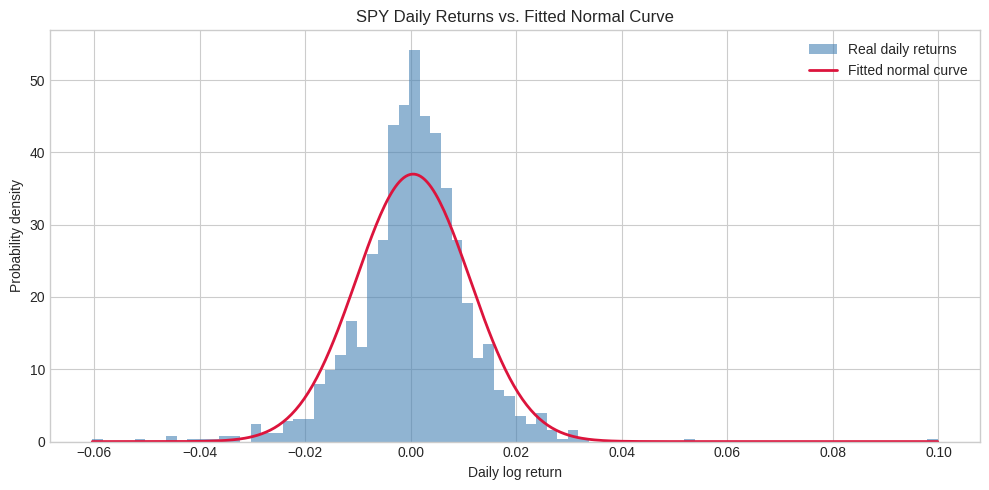

Mean:            0.00046
Std deviation:   0.01079
Skewness:        0.162
Excess kurtosis: 7.990


In [16]:
## Section 4: Testing for the Bell Curve

#We overlay a normal (bell) curve on the histogram of real returns, using the same mean and standard deviation. If the bell curve fits well, the histogram should match the curve closely.

#Skewness measures asymmetry: negative means a longer left tail (big drops are more common). **Excess kurtosis** measures tail weight: a normal distribution has 0, and positive values mean "fat tails," where extreme days happen more often than the bell curve predicts.

mu, sigma = log_ret.mean(), log_ret.std()
skew = stats.skew(log_ret)
exkurt = stats.kurtosis(log_ret)  # Fisher definition: normal = 0

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(log_ret, bins=80, density=True, alpha=0.6, color="steelblue",
        label="Real daily returns")
x = np.linspace(log_ret.min(), log_ret.max(), 400)
ax.plot(x, stats.norm.pdf(x, mu, sigma), color="crimson", linewidth=2,
        label="Fitted normal curve")
ax.set_title(f"{TICKER} Daily Returns vs. Fitted Normal Curve")
ax.set_xlabel("Daily log return")
ax.set_ylabel("Probability density")
ax.legend()
plt.tight_layout()
plt.show()

print(f"Mean:            {mu:.5f}")
print(f"Std deviation:   {sigma:.5f}")
print(f"Skewness:        {skew:.3f}")
print(f"Excess kurtosis: {exkurt:.3f}")

#Reading the output: If the excess kurtosis is well above 0, the real data has fatter tails than the bell curve. The histogram usually shows this as sharp peaks in the center and more mass in the far ends than the red curve suggests. Stock returns typically have excess kurtosis between roughly 2 and 10 at daily frequency, which is why the simple normal model is an approximation rather than a perfect description.

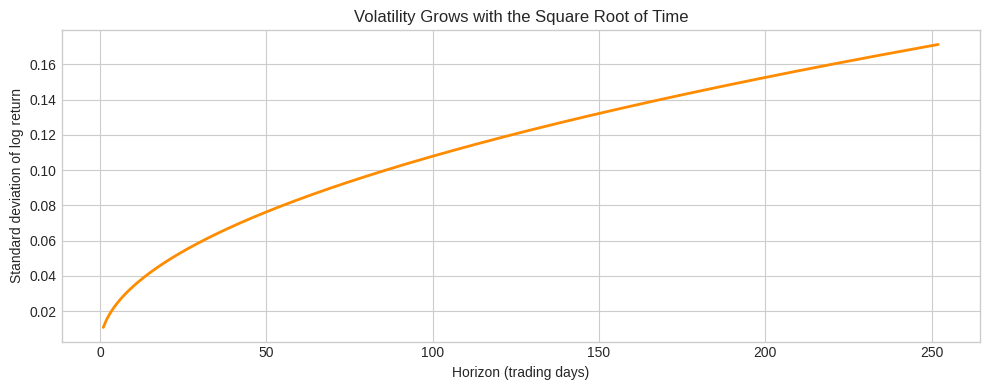

Daily volatility:      1.0785%
Annualized volatility: 17.12%


In [17]:
## Section 5: Volatility and the √252 Rule

#Volatility is the standard deviation of returns. Daily volatility is hard to compare across assets, so we annualize it. Returns are roughly independent from day to day, so variances add up over time. Variance grows linearly with time, which means standard deviation grows with the square root of time. There are about 252 trading days in a year, so annual volatility equals daily volatility times √252.

daily_vol = sigma
annual_vol = daily_vol * np.sqrt(252)

# Show that volatility scales with the square root of time
horizons = np.arange(1, 253)
vol_by_horizon = daily_vol * np.sqrt(horizons)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(horizons, vol_by_horizon, color="darkorange", linewidth=2)
ax.set_title("Volatility Grows with the Square Root of Time")
ax.set_xlabel("Horizon (trading days)")
ax.set_ylabel("Standard deviation of log return")
plt.tight_layout()
plt.show()

print(f"Daily volatility:      {daily_vol:.4%}")
print(f"Annualized volatility: {annual_vol:.2%}")

#Reading the output: The annualized figure is the typical one-standard-deviation move over a year. The curve shows the square-root rule visually: doubling the horizon increases the expected spread by about 41% (√2), not 100%.

Band Real data Normal model Difference
 ±1σ    75.68%       68.27%     +7.41%
 ±2σ    95.37%       95.45%     -0.08%
 ±3σ    98.96%       99.73%     -0.77%


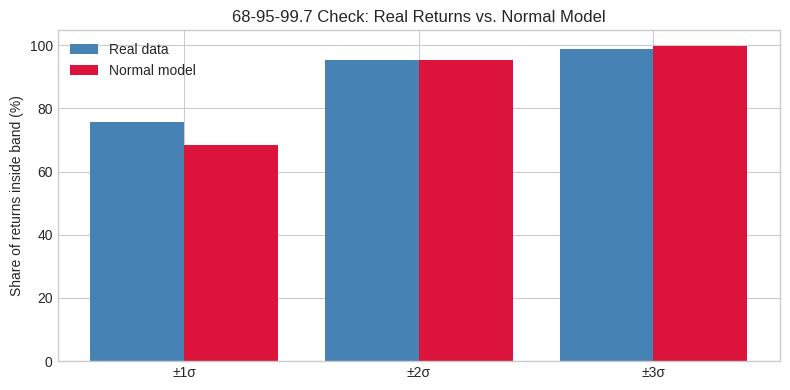

In [18]:
## Section 6: The 68-95-99.7 Rule Applied to Returns

#For a true normal distribution, about 68% of values fall within ±1σ of the mean, 95% within ±2σ, and 99.7% within ±3σ. We count how often real daily returns fall in those bands and compare the results with the theoretical normal values from `scipy.stats.norm`. Differences show exactly where the bell curve misjudges the real market.

z_levels = [1, 2, 3]
rows = []
for k in z_levels:
    lo, hi = mu - k * sigma, mu + k * sigma
    empirical = ((log_ret >= lo) & (log_ret <= hi)).mean()
    theoretical = stats.norm.cdf(k) - stats.norm.cdf(-k)
    rows.append({"Band": f"±{k}σ",
                 "Real data": f"{empirical:.2%}",
                 "Normal model": f"{theoretical:.2%}",
                 "Difference": f"{(empirical - theoretical):+.2%}"})

table = pd.DataFrame(rows)
print(table.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
emp = [((log_ret >= mu - k*sigma) & (log_ret <= mu + k*sigma)).mean() * 100 for k in z_levels]
theo = [(stats.norm.cdf(k) - stats.norm.cdf(-k)) * 100 for k in z_levels]
xpos = np.arange(len(z_levels))
ax.bar(xpos - 0.2, emp, 0.4, label="Real data", color="steelblue")
ax.bar(xpos + 0.2, theo, 0.4, label="Normal model", color="crimson")
ax.set_xticks(xpos, [f"±{k}σ" for k in z_levels])
ax.set_ylabel("Share of returns inside band (%)")
ax.set_title("68-95-99.7 Check: Real Returns vs. Normal Model")
ax.legend()
plt.tight_layout()
plt.show()

#Reading the output: The real data usually has slightly more returns inside ±1σ (the peak is sharper) and a similar or slightly smaller share inside ±2σ and ±3σ, which is a fingerprint of fat tails: most days are calm, but the rare big days fall further out than the normal model expects.

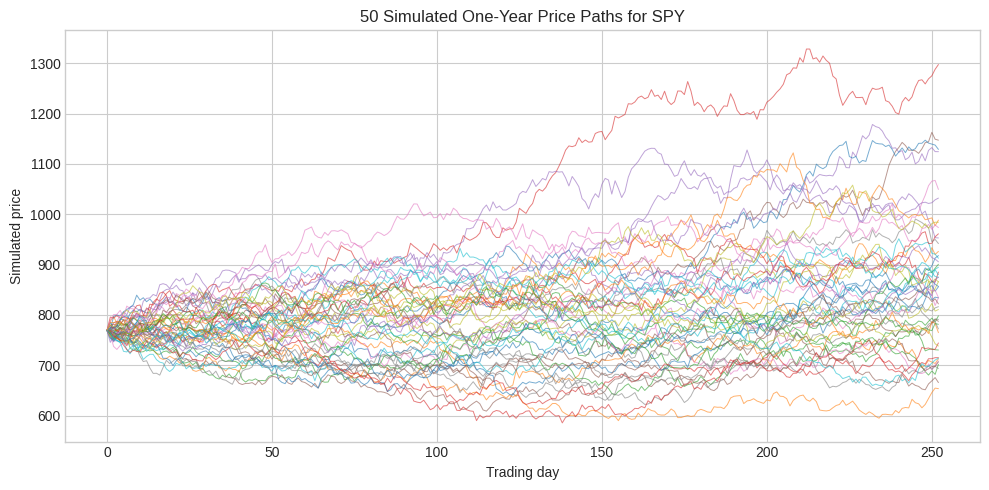

Starting price: 769.27
Simulated paths: 10,000, days each: 252


In [19]:
## Section 7: Simulating a Stock

#Now we use the bell curve as a generative model. Each day's log return is drawn from a normal distribution with our estimated mean and volatility. Starting from today's price and compounding 252 daily draws gives one possible one-year path. We simulate 10,000 such paths with the seed fixed at 42, then plot a sample of 50.

N_PATHS, N_DAYS = 10_000, 252
S0 = float(prices.iloc[-1])

np.random.seed(42)
daily_shocks = np.random.normal(mu, sigma, size=(N_PATHS, N_DAYS))
log_paths = np.cumsum(daily_shocks, axis=1)
price_paths = S0 * np.exp(np.hstack([np.zeros((N_PATHS, 1)), log_paths]))

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(price_paths[:50].T, linewidth=0.7, alpha=0.6)
ax.set_title(f"50 Simulated One-Year Price Paths for {TICKER}")
ax.set_xlabel("Trading day")
ax.set_ylabel("Simulated price")
plt.tight_layout()
plt.show()

print(f"Starting price: {S0:.2f}")
print(f"Simulated paths: {price_paths.shape[0]:,}, days each: {N_DAYS}")

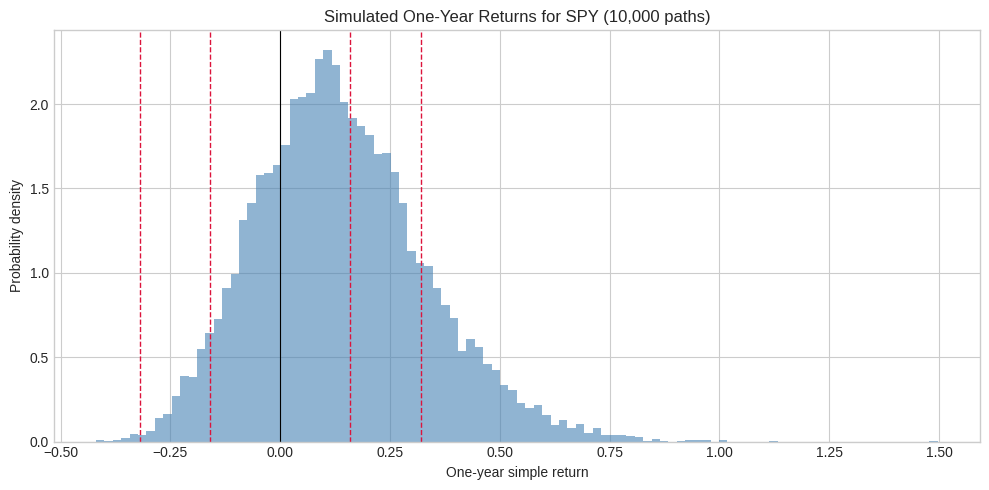

Move Analytic P(|move|>t) Simulated
±16%               47.18%    46.91%
±32%               17.59%    16.81%
±48%                5.42%     5.17%


In [20]:
## Section 8: Final Price Distribution

#Each simulated path ends at a one-year price. Converting those endings into returns gives the distribution of possible one-year outcomes under the model. Because the daily returns are normal, the sum of 252 of them is also normal (by the central limit theorem and the fact that sums of normals are normal). This lets us compute exact probabilities for large moves using `scipy.stats.norm`. We check ±16%, ±32%, and ±48%, which correspond roughly to 1, 2, and 3 annual standard deviations on a simple-return basis.

final_log = log_paths[:, -1]                # total log return per path
simple_ret = np.exp(final_log) - 1          # convert to simple one-year return

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(simple_ret, bins=100, density=True, alpha=0.6, color="steelblue")
ax.axvline(0, color="black", linewidth=0.8)
for t in [-0.16, 0.16, -0.32, 0.32]:
    ax.axvline(t, color="crimson", linestyle="--", linewidth=1)
ax.set_title(f"Simulated One-Year Returns for {TICKER} (10,000 paths)")
ax.set_xlabel("One-year simple return")
ax.set_ylabel("Probability density")
plt.tight_layout()
plt.show()

# Analytic probabilities under the normal model for the summed log return
mu_year = mu * N_DAYS
sd_year = sigma * np.sqrt(N_DAYS)
thresholds = [0.16, 0.32, 0.48]
rows = []
for t in thresholds:
    lo_log, hi_log = np.log(1 - t), np.log(1 + t)
    p_up = 1 - stats.norm.cdf(hi_log, mu_year, sd_year)
    p_down = stats.norm.cdf(lo_log, mu_year, sd_year)
    sim_p = np.mean((simple_ret > t) | (simple_ret < -t))
    rows.append({"Move": f"±{t:.0%}",
                 "Analytic P(|move|>t)": f"{p_up + p_down:.2%}",
                 "Simulated": f"{sim_p:.2%}"})
print(pd.DataFrame(rows).to_string(index=False))

#Reading the output: The analytic and simulated columns should agree closely, which confirms the simulation is correct. The analytic formula is exact for this model, so it is a good check on the code. Note that a ±48% move in one year is very rare under this model, but the real world sometimes produces such moves, as Section 10 will show.

In [21]:
## Section 10: Interpreting the Results

# We now compare the model's yearly probabilities with what actually happened in the five years of real data. We use overlapping 252-day windows so we have many yearly observations. Then we discuss where the bell curve breaks down.

# Where the model breaks: Real markets have **fat tails** (extreme days are more common than normal), **volatility clustering** (calm and turbulent periods come in bunches, so volatility is not constant), and **skew** (crashes tend to be sharper than rallies). A constant-volatility normal model understates the chance of large, sudden losses.

# Disclaimer: This notebook is for education only. It is not investment advice, and past data does not guarantee future results.

window = N_DAYS
real_yearly = np.log(prices).diff(window).dropna()
real_simple = np.exp(real_yearly) - 1

rows = []
for t in [0.16, 0.32, 0.48]:
    model_p = 1 - (stats.norm.cdf(np.log(1 + t), mu_year, sd_year)
                   - stats.norm.cdf(np.log(1 - t), mu_year, sd_year))
    emp_p = np.mean((real_simple > t) | (real_simple < -t))
    rows.append({"Move": f"±{t:.0%}",
                 "Normal model": f"{model_p:.2%}",
                 "Real data (rolling 1y)": f"{emp_p:.2%}",
                 "Real / model": f"{emp_p / model_p:.2f}x" if model_p > 0 else "n/a"})

print(pd.DataFrame(rows).to_string(index=False))
print(f"\nOverlapping one-year windows used: {len(real_simple)}")

# Reading the output: Ratios above 1 mean the real market produced large yearly moves more often than the bell curve predicts. Because the windows overlap and cover only a few years, treat these numbers as illustrative rather than precise. The lesson is directional: the normal model is useful for typical moves but tends to underestimate rare, extreme ones, which is why practitioners pair it with fat-tailed models and stress tests.

Move Normal model Real data (rolling 1y) Real / model
±16%       47.18%                 63.21%        1.34x
±32%       17.59%                  8.47%        0.48x
±48%        5.42%                  0.00%        0.00x

Overlapping one-year windows used: 1003
